# 04 - Modelo gravitacional

## Importar librerías

In [1]:
from pathlib import Path
from zipfile import ZipFile
from textwrap import shorten
from IPython.display import HTML, display
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import duckdb
import pyfixest as pf
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.special import logsumexp
from scipy.stats import t as student_t

## Mejorar la visualización

In [2]:
# Que muestre todas las columnas
pd.options.display.max_columns = None
# En los dataframes, mostrar los float con dos decimales
pd.options.display.float_format = '{:,.2f}'.format

## Establecer las rutas y parámetros

In [3]:
RAIZ = Path.cwd().resolve()
for carpeta in [RAIZ, *RAIZ.parents]:
    if (carpeta / 'requirements.txt').is_file() and (carpeta / 'data').is_dir():
        RAIZ = carpeta
        break
else:
    raise FileNotFoundError('Abra el notebook desde el proyecto.')

RAW = RAIZ / 'data/raw'
INTERIM = RAIZ / 'data/interim'
PROCESSED = RAIZ / 'data/processed'
REPORTS = RAIZ / 'data/reports/04_modelo_gravitacional'
REPORTS.mkdir(parents=True, exist_ok=True)
YEARS = list(range(2017, 2025))
ESCALA_USD = 1_000_000
PRINCIPALES = ['gdp_real_usd', 'dist', 'contig', 'comlang_off', 'fta_in_force', 'wto_d', 'oecd_d']
REGRESORES = ['ln_gdp_real_usd', 'ln_dist', 'contig', 'comlang_off', 'fta_in_force', 'wto_d', 'oecd_d']
CLAVES = ['hs6', 'iso3_d', 'year']

## Cargar las bases preparadas

In [4]:
baci = pd.read_parquet(PROCESSED / 'baci/baci_exports_COL_2017_2024_HS2017_V202601.parquet',
    columns = ['year', 'partner_iso3', 'hs6', 'trade_value_usd'])
variables = pd.read_parquet(PROCESSED / 'variables/base_final_variables_COL_2017_2024.parquet')
catalogo_destinos = pd.read_parquet(PROCESSED / 'variables/catalogo_destinos_variables.parquet')
catalogo_productos = pd.read_csv(RAW / 'baci/product_codes_HS17_V202601.csv', dtype = {'code': 'string'})
assert variables[PRINCIPALES].notna().all().all()
assert not baci.duplicated(['hs6', 'partner_iso3', 'year']).any()
assert baci['trade_value_usd'].gt(0).all()

## Preparar los márgenes de estimación

In [5]:
covariables = variables.sort_values(['year', 'iso3_d']).reset_index(drop = True).copy()
for columna in PRINCIPALES[2:]:
    covariables[columna] = covariables[columna].astype('int8')
for columna in ['gdp_real_usd', 'dist']:
    assert covariables[columna].gt(0).all()
    covariables['ln_' + columna] = np.log(covariables[columna])
observadas = baci.loc[baci['partner_iso3'].isin(covariables['iso3_d']),
    ['hs6', 'partner_iso3', 'year', 'trade_value_usd']].rename(columns = {'partner_iso3': 'iso3_d'}).copy()
totales_destino = observadas.groupby(['iso3_d', 'year'], as_index = False)['trade_value_usd'].sum()
sumas_destino = covariables.merge(totales_destino, on = ['iso3_d', 'year'], how = 'left', validate = 'one_to_one')
sumas_destino['trade_value_usd'] = sumas_destino['trade_value_usd'].fillna(0)
sumas_destino['exportaciones_millones'] = sumas_destino['trade_value_usd'] / ESCALA_USD
productos = sorted(baci['hs6'].unique())
producto_anio = pd.MultiIndex.from_product([productos, YEARS], names = ['hs6', 'year']).to_frame(index = False)
totales_producto = observadas.groupby(['hs6', 'year'], as_index = False)['trade_value_usd'].sum()
producto_anio = producto_anio.merge(totales_producto, on = ['hs6', 'year'], how = 'left', validate = 'one_to_one')
producto_anio['total_hs6_anio_usd'] = producto_anio.pop('trade_value_usd').fillna(0)
producto_anio['efecto_fijo_finito'] = producto_anio['total_hs6_anio_usd'].gt(0)
producto_anio['year'] = producto_anio['year'].astype('int16')
numero_destinos = covariables['iso3_d'].nunique()
numero_efectos = int(producto_anio['efecto_fijo_finito'].sum())
filas_panel = len(producto_anio) * numero_destinos
filas_estimacion = numero_efectos * numero_destinos
assert filas_panel == 7_769_680 and filas_estimacion == 6_558_327

## Verificar la presencia mundial antes de construir ceros

In [6]:
presencia_destinos, presencia_productos = [], []
with duckdb.connect() as con:
    con.execute("SET threads=2")
    con.execute("SET memory_limit='256MB'")
    for anio in YEARS:
        conteos_paises, conteos_bienes = [], []
        with ZipFile(RAW / 'baci/BACI_HS17_V202601.zip') as paquete:
            with paquete.open(f'BACI_HS17_Y{anio}_V202601.csv') as entrada:
                for bloque in pd.read_csv(entrada, usecols = ['j', 'k'], dtype = {'k': 'string'}, chunksize = 500_000):
                    conteos_paises.append(bloque['j'].value_counts())
                    conteos_bienes.append(bloque['k'].str.strip().str.zfill(6).value_counts())
        paises = pd.concat(conteos_paises).groupby(level=0).sum().rename_axis('codigo_baci').reset_index(name='flujos_mundo')
        bienes = pd.concat(conteos_bienes).groupby(level=0).sum().rename_axis('hs6').reset_index(name='flujos_mundo_producto')
        presencia_destinos.append(paises.assign(year = anio))
        presencia_productos.append(bienes.assign(year = anio))
cobertura_destinos = covariables[['iso3_d', 'year']].merge(catalogo_destinos[['iso3_d', 'codigo_baci']], on='iso3_d', validate='many_to_one')
cobertura_destinos = cobertura_destinos.merge(pd.concat(presencia_destinos), on=['codigo_baci', 'year'], how='left', validate='one_to_one')
cobertura_productos = producto_anio[['hs6', 'year']].merge(pd.concat(presencia_productos), on=['hs6', 'year'], how='left', validate='one_to_one')
assert cobertura_destinos['flujos_mundo'].gt(0).all() and cobertura_productos['flujos_mundo_producto'].gt(0).all()

## Estimar PPML con efectos HS6–año

In [7]:
formula_hs6 = 'exportaciones_millones ~ ' + ' + '.join(REGRESORES) + ' | hs6_anio'
formula_perfil = 'exportaciones_millones ~ ' + ' + '.join(REGRESORES) + ' | year'
modelo = pf.fepois(formula_perfil, data = sumas_destino,
    vcov = {'CRV1': 'iso3_d'}, ssc = pf.ssc(k_adj = False, G_adj = True),
    separation_check = ['fe', 'ir'], iwls_tol = 1e-10, iwls_maxiter = 100)
assert modelo.convergence and int(modelo._N) == len(sumas_destino)
assert int(getattr(modelo, 'n_separation_na', 0)) == 0
assert set(modelo.coef().index) == set(REGRESORES)

## Consultar la tabla de coeficientes

In [8]:
def tabla_coeficientes(modelo, n_hs6, numero_efectos, grupos):
    coef = modelo.coef()
    if set(coef.index) != set(REGRESORES):
        raise ValueError("Algún regresor fue eliminado; revisar identificación antes de publicar.")
    k = len(coef) + numero_efectos
    if grupos < 2 or n_hs6 <= k:
        raise ValueError("Muestra insuficiente para la inferencia agrupada.")
    # El modelo auxiliar se estima con k_adj=False y G_adj=True.
    factor_nk = (n_hs6 - 1) / (n_hs6 - k)
    se = modelo.se().reindex(coef.index) * np.sqrt(factor_nk)
    estadistico = coef / se
    critico = student_t.ppf(0.975, grupos - 1)
    tabla = pd.DataFrame({
        "variable": coef.index, "coeficiente": coef.to_numpy(), "error_estandar": se.to_numpy(),
        "estadistico_t": estadistico.to_numpy(),
        "p_valor": 2 * student_t.sf(np.abs(estadistico), grupos - 1),
        "ic95_inferior": (coef - critico * se).to_numpy(),
        "ic95_superior": (coef + critico * se).to_numpy(),
    })
    tabla["interpretacion"] = np.where(tabla.variable.str.startswith("ln_"), "elasticidad", "cambio 0 a 1")
    tabla["cambio_porcentual_dummy"] = np.where(
        tabla.variable.str.startswith("ln_"), np.nan, 100 * np.expm1(tabla.coeficiente)
    )
    return tabla, float(factor_nk)

coeficientes, factor_crv1 = tabla_coeficientes(modelo, filas_estimacion, numero_efectos, numero_destinos)
display(HTML(coeficientes.to_html(index = False, float_format = lambda x: f'{x:.5f}',
    formatters = {'p_valor': lambda x: f'{x:.3g}'}, na_rep = '')))

variable,coeficiente,error_estandar,estadistico_t,p_valor,ic95_inferior,ic95_superior,interpretacion,cambio_porcentual_dummy
ln_gdp_real_usd,0.83591,0.05659,14.77123,1.12e-33,0.72430,0.94751,elasticidad,
ln_dist,-1.16746,0.13489,-8.65504,1.79e-15,-1.43348,-0.90144,elasticidad,
contig,0.71483,0.26238,2.72440,0.00702,0.19738,1.23229,cambio 0 a 1,104.38459
comlang_off,0.34787,0.25438,1.36750,0.173,-0.15381,0.84954,cambio 0 a 1,41.60416
fta_in_force,-0.46934,0.25202,-1.86234,0.0641,-0.96635,0.02767,cambio 0 a 1,-37.45847
wto_d,0.24619,0.49698,0.49536,0.621,-0.73394,1.22631,cambio 0 a 1,27.91397
oecd_d,0.34251,0.30886,1.10894,0.269,-0.26661,0.95163,cambio 0 a 1,40.84800


## Recuperar los ajustes por producto y destino

In [9]:
destinos_ajustados = sumas_destino.copy()
destinos_ajustados['indice_gravitacional'] = destinos_ajustados[REGRESORES].to_numpy(dtype=float) @ modelo.coef().reindex(REGRESORES).to_numpy()
denominadores = destinos_ajustados.groupby('year')['indice_gravitacional'].agg(logsumexp)
destinos_ajustados['participacion_estimada_destino'] = np.exp(
    destinos_ajustados['indice_gravitacional'] - destinos_ajustados['year'].map(denominadores))
efectos_hs6 = producto_anio.copy()
positivos = efectos_hs6['efecto_fijo_finito']
efectos_hs6['efecto_fijo_hs6_anio_millones'] = np.nan
efectos_hs6.loc[positivos, 'efecto_fijo_hs6_anio_millones'] = (
    np.log(efectos_hs6.loc[positivos, 'total_hs6_anio_usd'] / ESCALA_USD)
    - efectos_hs6.loc[positivos, 'year'].map(denominadores))
total_anual = observadas.groupby('year')['trade_value_usd'].sum()
ajuste_auxiliar = destinos_ajustados['year'].map(total_anual) * destinos_ajustados['participacion_estimada_destino']
assert np.allclose(ajuste_auxiliar, modelo.predict(type='response') * ESCALA_USD, rtol=1e-6, atol=1)

## Construir el panel y calcular las brechas

In [10]:
def construir_bloque(producto_anio, destinos, observadas):
    if producto_anio.year.nunique() != 1 or destinos.year.nunique() != 1:
        raise ValueError("Cada bloque debe corresponder a un único año.")
    year = int(producto_anio.year.iloc[0])
    if set(destinos.year) != {year}:
        raise ValueError("Años distintos al formar el bloque.")
    if producto_anio.duplicated(["hs6", "year"]).any() or destinos.duplicated(["iso3_d", "year"]).any():
        raise ValueError("Claves duplicadas al construir el panel.")
    panel = producto_anio[["hs6", "total_hs6_anio_usd", "efecto_fijo_finito"]].merge(destinos, how="cross")
    panel = panel.merge(observadas, on=CLAVES, how="left", validate="one_to_one")
    panel["registro_baci"] = panel["trade_value_usd"].notna()
    panel["cero_construido"] = ~panel["registro_baci"]
    panel["trade_value_usd"] = panel["trade_value_usd"].fillna(0)
    panel["exportaciones_estimadas_usd"] = panel["total_hs6_anio_usd"] * panel["participacion_estimada_destino"]
    panel["brecha_usd"] = panel["exportaciones_estimadas_usd"] - panel["trade_value_usd"]
    # No se divide por exportaciones observadas: hay ceros legítimos en el panel.
    panel["brecha_relativa"] = np.divide(
        panel["brecha_usd"].to_numpy(), panel["exportaciones_estimadas_usd"].to_numpy(),
        out=np.full(len(panel), np.nan), where=panel["exportaciones_estimadas_usd"].to_numpy() > 0,
    )
    panel["estado_ajuste"] = np.where(
        panel["efecto_fijo_finito"], "ajuste_en_muestra", "limite_cero_hs6_anio_sin_flujos"
    )
    panel["hs4"] = panel["hs6"].str[:4]
    panel["year"] = panel["year"].astype("int16")
    columnas = ["iso3_o", "hs6", "hs4", "iso3_d", "year", "trade_value_usd", "registro_baci", "cero_construido",
                *PRINCIPALES, "estado_datos", "exportaciones_estimadas_usd", "brecha_usd", "brecha_relativa",
                "efecto_fijo_finito", "estado_ajuste"]
    resultado = panel[columnas].copy()
    if resultado[PRINCIPALES].isna().any().any() or not np.isfinite(resultado.exportaciones_estimadas_usd).all():
        raise ValueError("Faltantes o ajustes no finitos en el panel.")
    return resultado

def guardar_panel(archivo, observadas, destinos_ajustados, efectos_hs6, tamano_bloque=200):
    archivo = Path(archivo)
    archivo.parent.mkdir(parents=True, exist_ok=True)
    temporal = archivo.with_suffix(".parquet.tmp")
    anuales, mercados, escritor = [], [], None
    acumulados, esperados = 0.0, float(observadas.trade_value_usd.sum())
    try:
        for year in YEARS:
            productos = efectos_hs6.loc[efectos_hs6.year.eq(year)].sort_values("hs6")
            destinos = destinos_ajustados.loc[destinos_ajustados.year.eq(year)].drop(
                columns=["trade_value_usd", "exportaciones_millones"]
            ).sort_values("iso3_d")
            obs = observadas.loc[observadas.year.eq(year)]
            for inicio in range(0, len(productos), tamano_bloque):
                seleccion = productos.iloc[inicio:inicio + tamano_bloque]
                bloque = construir_bloque(seleccion, destinos, obs.loc[obs.hs6.isin(seleccion.hs6)])
                tabla = pa.Table.from_pandas(bloque, preserve_index=False)
                if escritor is None:
                    escritor = pq.ParquetWriter(temporal, tabla.schema, compression="zstd")
                escritor.write_table(tabla)
                acumulados += float(bloque.trade_value_usd.sum())
                anuales.append({
                    "year": year, "filas": len(bloque), "flujos_positivos": int(bloque.registro_baci.sum()),
                    "ceros_construidos": int(bloque.cero_construido.sum()),
                    "filas_efecto_fijo_finito": int(bloque.efecto_fijo_finito.sum()),
                    "valor_observado_usd": float(bloque.trade_value_usd.sum()),
                    "valor_estimado_usd": float(bloque.exportaciones_estimadas_usd.sum()),
                    "brecha_usd": float(bloque.brecha_usd.sum()),
                })
                mercados.append(bloque.groupby("iso3_d", as_index=False)[
                    ["trade_value_usd", "exportaciones_estimadas_usd", "brecha_usd"]
                ].sum())
        escritor.close()
        escritor = None
        if not np.isclose(acumulados, esperados, rtol=1e-12, atol=0.01):
            raise ValueError("Cambió el valor comercial al construir el panel.")
        resumen = pd.DataFrame(anuales).groupby("year", as_index=False).sum()
        n_esperado = len(efectos_hs6) * destinos_ajustados.iso3_d.nunique()
        if resumen.filas.sum() != n_esperado or resumen.flujos_positivos.sum() != len(observadas):
            raise ValueError("Cambió el número de combinaciones o registros BACI.")
        if not np.allclose(resumen.valor_estimado_usd, resumen.valor_observado_usd, rtol=1e-9, atol=0.01):
            raise ValueError("Los ajustes no conservan los totales impuestos por los efectos HS6–año.")
        temporal.replace(archivo)
    finally:
        if escritor is not None:
            escritor.close()
    resumen["porcentaje_ceros"] = 100 * resumen.ceros_construidos / resumen.filas
    destinos = pd.concat(mercados).groupby("iso3_d", as_index=False).sum()
    return resumen, destinos

## Guardar el panel por bloques y consultar el resumen anual

In [11]:
archivo_panel = PROCESSED / 'gravitacional/panel_gravitacional_COL_2017_2024_HS2017.parquet'
archivo_nuevo = INTERIM / 'panel_gravitacional_verificado.parquet'
resumen_anual, resumen_destinos = guardar_panel(archivo_nuevo, observadas, destinos_ajustados, efectos_hs6, tamano_bloque = 200)
assert int(resumen_anual['filas'].sum()) == filas_panel
assert int(resumen_anual['flujos_positivos'].sum()) == len(observadas)
if archivo_panel.exists():
    actual, previo = pq.ParquetFile(archivo_nuevo), pq.ParquetFile(archivo_panel)
    assert actual.metadata.num_rows == previo.metadata.num_rows
    for nuevo, anterior in zip(actual.iter_batches(batch_size=100_000), previo.iter_batches(batch_size=100_000), strict=True):
        pd.testing.assert_frame_equal(nuevo.to_pandas(), anterior.to_pandas(), rtol=1e-10, atol=1e-6)
    actual.close()
    previo.close()
    archivo_nuevo.unlink()
else:
    archivo_panel.parent.mkdir(parents=True, exist_ok=True)
    archivo_nuevo.replace(archivo_panel)
resumen_anual

,year,filas,flujos_positivos,ceros_construidos,filas_efecto_fijo_finito,valor_observado_usd,valor_estimado_usd,brecha_usd,porcentaje_ceros
0,2017,971210,47138,924072,816565,"41,678,559,607.00","41,678,559,607.00",-0.00,95.15
1,2018,971210,48735,922475,817550,"44,999,197,276.00","44,999,197,276.00",0.00,94.98
2,2019,971210,50120,921090,813610,"41,616,825,854.00","41,616,825,854.00",-0.00,94.84
3,2020,971210,49028,922182,807700,"33,241,950,285.00","33,241,950,285.00",-0.00,94.95
4,2021,971210,52745,918465,822081,"43,024,489,498.00","43,024,489,498.00",0.00,94.57
5,2022,971210,53415,917795,824839,"60,847,237,132.00","60,847,237,132.00",0.00,94.50
6,2023,971210,55496,915714,832128,"52,881,842,756.00","52,881,842,756.00",-0.00,94.29
7,2024,971210,55441,915769,823854,"50,975,315,139.00","50,975,315,139.00",-0.00,94.29


## Graficar el ajuste por destino

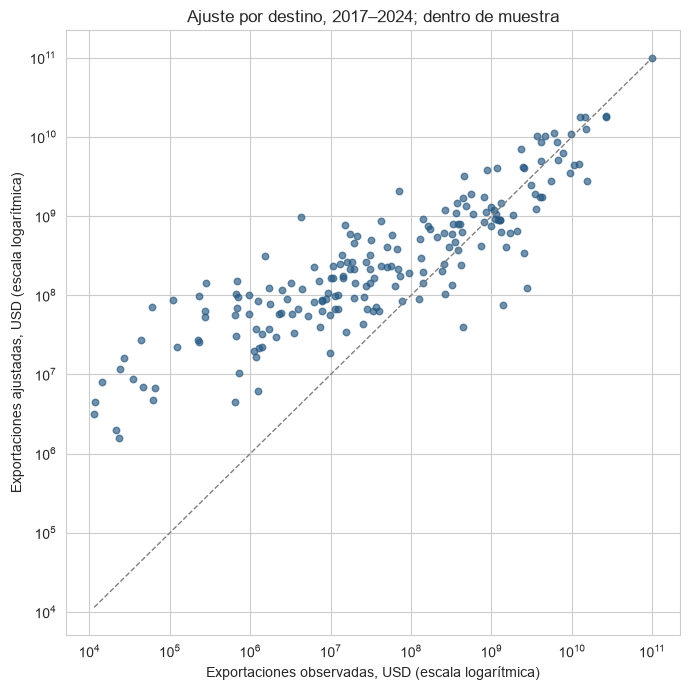

In [12]:
fig, ax = plt.subplots(figsize = (7, 7))
x = resumen_destinos['trade_value_usd']
y = resumen_destinos['exportaciones_estimadas_usd']
ax.scatter(x, y, alpha = .65, s = 22, color = '#245882')
limites = [min(x.min(), y.min()), max(x.max(), y.max())]
ax.plot(limites, limites, color = 'grey', linestyle = '--', linewidth = 1)
ax.set(xscale = 'log', yscale = 'log',
    xlabel = 'Exportaciones observadas, USD (escala logarítmica)',
    ylabel = 'Exportaciones ajustadas, USD (escala logarítmica)',
    title = 'Ajuste por destino, 2017–2024; dentro de muestra')
fig.tight_layout()
fig.savefig(REPORTS / 'ajuste_destinos.png', dpi = 180, bbox_inches = 'tight')
plt.show()

## Calcular las brechas positivas con exportación efectiva

In [13]:
with duckdb.connect() as con:
    con.execute("SET threads=2")
    con.execute("SET memory_limit='512MB'")
    ranking_base = con.execute("""SELECT hs6, iso3_d,
        sum(trade_value_usd) FILTER(WHERE brecha_usd>0) AS observado_usd,
        sum(exportaciones_estimadas_usd) FILTER(WHERE brecha_usd>0) AS ajuste_usd,
        sum(brecha_usd) FILTER(WHERE brecha_usd>0) AS brecha_positiva_usd,
        sum(brecha_usd) AS brecha_neta_contexto_usd,
        count(*) FILTER(WHERE brecha_usd>0)::INTEGER AS anios_con_brecha_positiva
        FROM read_parquet(?) WHERE trade_value_usd>0
        GROUP BY hs6,iso3_d HAVING sum(brecha_usd) FILTER(WHERE brecha_usd>0)>0""", [str(archivo_panel)]).df()
ranking_base['brecha_relativa_ponderada'] = ranking_base['brecha_positiva_usd'] / ranking_base['ajuste_usd']
ranking_base = ranking_base.merge(catalogo_productos.rename(columns={'code':'hs6', 'description':'nombre_producto_hs6_baci'}), on='hs6', validate='many_to_one')
ranking_base = ranking_base.merge(catalogo_destinos[['iso3_d', 'nombre_destino']].rename(columns={'nombre_destino':'nombre_pais_destino'}), on='iso3_d', validate='many_to_one')
ranking_base = ranking_base.sort_values(['brecha_positiva_usd', 'hs6', 'iso3_d'], ascending=[False, True, True]).reset_index(drop=True)
ranking_general = ranking_base.head(15).copy()
ranking_general.insert(0, 'ranking', range(1, len(ranking_general) + 1))
columnas_ranking = ['ranking', 'hs6', 'nombre_producto_hs6_baci', 'nombre_pais_destino',
    'observado_usd', 'ajuste_usd', 'brecha_positiva_usd', 'brecha_relativa_ponderada',
    'brecha_neta_contexto_usd', 'anios_con_brecha_positiva']

## Consultar las mayores brechas positivas acumuladas de 2017–2024

In [14]:
with pd.option_context('display.max_colwidth', None):
    display(ranking_general[columnas_ranking])

,ranking,hs6,nombre_producto_hs6_baci,nombre_pais_destino,observado_usd,ajuste_usd,brecha_positiva_usd,brecha_relativa_ponderada,brecha_neta_contexto_usd,anios_con_brecha_positiva
0,1,270112,"Coal: bituminous, whether or not pulverised, but not agglomerated",Estados Unidos de América,"2,164,383,172.00","14,102,767,226.68","11,938,384,054.68",0.85,"11,938,384,054.68",8
1,2,270112,"Coal: bituminous, whether or not pulverised, but not agglomerated",Panamá,"349,842,914.00","2,624,360,140.96","2,274,517,226.96",0.87,"2,274,517,226.96",8
2,3,270900,"Oils: petroleum oils and oils obtained from bituminous minerals, crude",Canadá,"818,138,226.00","3,050,784,337.48","2,232,646,111.48",0.73,"2,232,646,111.48",8
3,4,270119,"Coal: (other than anthracite and bituminous), whether or not pulverised but not agglomerated",Estados Unidos de América,"746,226,996.00","2,534,483,940.99","1,788,256,944.99",0.71,"1,788,256,944.99",8
4,5,270112,"Coal: bituminous, whether or not pulverised, but not agglomerated",Ecuador,"129,405.00","1,780,511,320.87","1,780,381,915.87",1.00,"1,780,381,915.87",8
5,6,270900,"Oils: petroleum oils and oils obtained from bituminous minerals, crude",Japón,"232,618,490.00","1,824,579,696.79","1,591,961,206.79",0.87,"1,591,961,206.79",5
6,7,270400,"Coke and semi-coke: of coal, lignite or peat, whether or not agglomerated: retort carbon",Estados Unidos de América,"18,975,327.00","1,399,487,200.68","1,380,511,873.68",0.99,"1,380,511,873.68",5
7,8,270112,"Coal: bituminous, whether or not pulverised, but not agglomerated",China,"236,756,077.00","1,569,266,052.54","1,332,509,975.54",0.85,"1,044,255,004.75",5
8,9,270900,"Oils: petroleum oils and oils obtained from bituminous minerals, crude",Ecuador,"705,599,305.00","2,034,716,299.22","1,329,116,994.22",0.65,"1,329,116,994.22",5
9,10,270112,"Coal: bituminous, whether or not pulverised, but not agglomerated",Perú,"252,782,932.00","1,542,114,419.99","1,289,331,487.99",0.84,"1,289,331,487.99",8


## Consultar las mayores brechas sin minerales y energía

In [15]:
excluido_me = (ranking_base['hs6'].str[:2].isin(['25', '26', '27'])
    | ranking_base['hs6'].str[:4].isin(['7102', '7103', '7106', '7108', '7110'])
    | ranking_base['hs6'].eq('720260'))
ranking_sin_me = ranking_base.loc[~excluido_me].head(15).copy()
ranking_sin_me.insert(0, 'ranking', range(1, len(ranking_sin_me) + 1))
with pd.option_context('display.max_colwidth', None):
    display(ranking_sin_me[columnas_ranking])

,ranking,hs6,nombre_producto_hs6_baci,nombre_pais_destino,observado_usd,ajuste_usd,brecha_positiva_usd,brecha_relativa_ponderada,brecha_neta_contexto_usd,anios_con_brecha_positiva
10,1,080390,"Fruit, edible: bananas, other than plantains, fresh or dried",Estados Unidos de América,"1,219,437,060.00","2,418,954,035.60","1,199,516,975.60",0.50,"1,199,516,975.60",8
13,2,090111,Coffee: not roasted or decaffeinated,México,"99,761,582.00","1,133,965,040.76","1,034,203,458.76",0.91,"1,034,203,458.76",8
15,3,090111,Coffee: not roasted or decaffeinated,Panamá,"651,324.00","734,262,547.90","733,611,223.90",1.00,"733,611,223.90",5
16,4,090111,Coffee: not roasted or decaffeinated,China,"473,885,291.00","1,151,191,185.72","677,305,894.72",0.59,"677,305,894.72",8
20,5,390410,"Vinyl chloride, other halogenated olefin polymers: poly(vinyl chloride), not mixed with any other substances, in primary forms",Estados Unidos de América,"200,081,115.00","741,494,254.50","541,413,139.50",0.73,"541,413,139.50",8
22,6,740400,Copper: waste and scrap,Estados Unidos de América,"37,739,441.00","554,114,707.55","516,375,266.55",0.93,"516,375,266.55",8
23,7,090111,Coffee: not roasted or decaffeinated,Ecuador,"27,342,106.00","539,404,688.74","512,062,582.74",0.95,"512,062,582.74",5
24,8,380892,Fungicides: other than containing goods specified in Subheading Note 1 to this Chapter: put up in forms or packings for retail sale or as preparations or articles,Estados Unidos de América,"22,308,803.00","531,558,895.15","509,250,092.15",0.96,"509,250,092.15",8
27,9,300490,"Medicaments: consisting of mixed or unmixed products n.e.c. in heading no. 3004, for therapeutic or prophylactic uses, packaged for retail sale",Estados Unidos de América,"26,696,726.00","508,129,653.69","481,432,927.69",0.95,"481,432,927.69",8
30,10,870323,"Vehicles: with only spark-ignition internal combustion reciprocating piston engine, cylinder capacity over 1500 but not over 3000cc",Estados Unidos de América,"9,300,592.00","457,850,995.99","448,550,403.99",0.98,"448,550,403.99",8


## Comparar las mayores brechas generales y sin minerales y energía

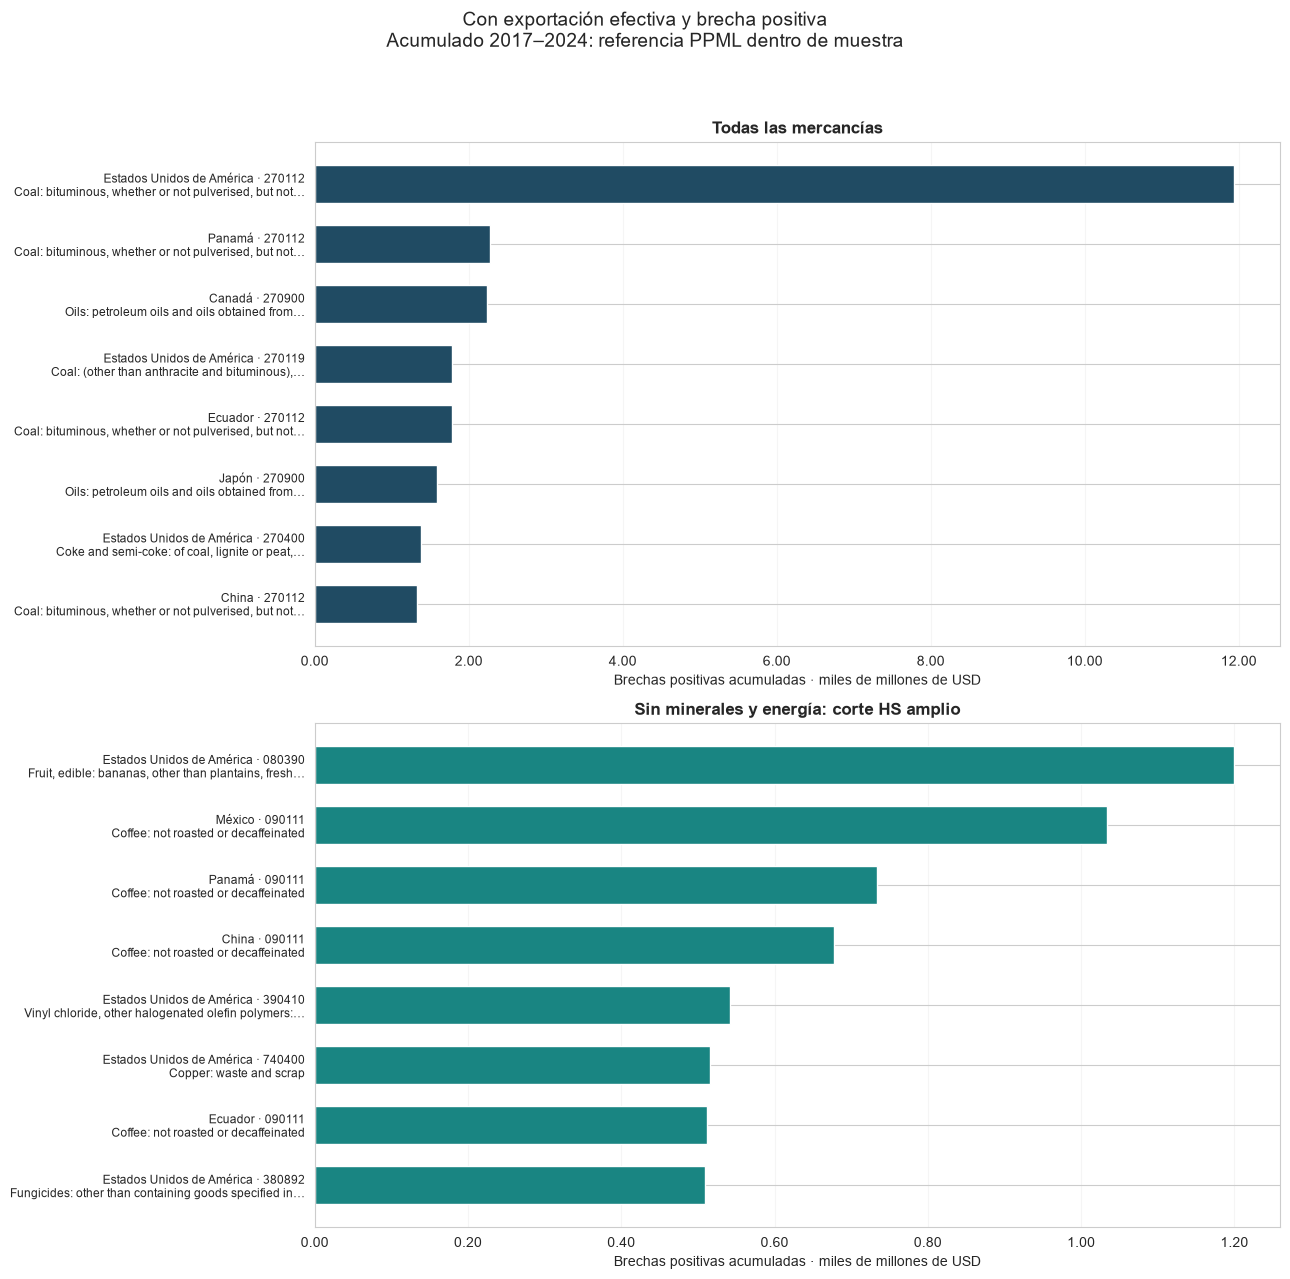

In [16]:
fig, axes = plt.subplots(2, 1, figsize = (13, 13))
for ax, tabla, color, titulo in zip(axes,
    [ranking_general.head(8), ranking_sin_me.head(8)],
    ['#204b63', '#198582'], ['Todas las mercancías', 'Sin minerales y energía: corte HS amplio']):
    etiquetas = [f'{fila.nombre_pais_destino} · {fila.hs6}\n{shorten(fila.nombre_producto_hs6_baci, width=53, placeholder="…")}'
        for fila in tabla.itertuples(index=False)]
    ax.barh(range(len(tabla)), tabla['brecha_positiva_usd'] / 1_000_000_000, color = color, height = .64)
    ax.set_yticks(range(len(tabla)), etiquetas, fontsize = 8.5)
    ax.invert_yaxis()
    ax.set_title(titulo, fontweight = 'bold', fontsize = 12)
    ax.set_xlabel('Brechas positivas acumuladas · miles de millones de USD')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f'{valor:,.2f}'))
    ax.grid(axis = 'x', alpha = .18)
    ax.set_axisbelow(True)
fig.suptitle('Con exportación efectiva y brecha positiva\nAcumulado 2017–2024: referencia PPML dentro de muestra', fontsize = 14)
fig.tight_layout(rect = (0, 0, 1, .95))
fig.savefig(REPORTS / 'mayores_brechas_positivas.png', dpi = 180, bbox_inches = 'tight')
plt.show()

## Guardar los resultados necesarios

In [17]:
for nombre, tabla in {
    'coeficientes_ppml': coeficientes, 'resumen_anual': resumen_anual,
    'resumen_destinos': resumen_destinos,
    'mayores_brechas_general': ranking_general[columnas_ranking],
    'mayores_brechas_sin_me': ranking_sin_me[columnas_ranking]
}.items():
    tabla.to_parquet(REPORTS / f'{nombre}.parquet', index = False, compression = 'zstd')